In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np

In [21]:
df= pd.read_csv("real_estate_dataset_1000.csv")


df.head()

,شناسه,address,metrazh,room,service wc,parking,ghedmat,toman
0,1,اصفهان، مرداویج، خیابان شیخ کلینی، کوچه 8، پلاک 7,129,3,2,دارد,28,6.651000e+09
1,2,تهران، پیروزی، خیابان نبرد شمالی، کوچه 6، پلاک...,205,4,2,دارد,14,1.491800e+10
2,3,مشهد، سجاد، بلوار سجاد، کوچه 35، پلاک 108,93,2,2,دارد,1,6.959000e+09
3,4,مشهد، سجاد، بلوار سجاد، کوچه 28، پلاک 88,72,2,1,ندارد,25,2.849000e+09
4,5,تهران، صادقیه، بلوار ستارخان، کوچه 23، پلاک 68,174,4,4,دارد,19,1.763800e+10


In [22]:
df.describe()

,شناسه,metrazh,room,service wc,ghedmat,toman
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1.000000e+03
mean,500.500000,161.148000,3.495000,2.56100,12.057000,2.096552e+10
std,288.819436,69.365017,1.178713,0.89838,9.616456,1.618886e+10
min,1.000000,49.000000,1.000000,1.00000,0.000000,2.586000e+09
25%,250.750000,103.000000,3.000000,2.00000,3.000000,1.011000e+10
50%,500.500000,152.000000,4.000000,3.00000,11.000000,1.621550e+10
75%,750.250000,210.250000,4.000000,3.00000,20.000000,2.642800e+10
max,1000.000000,343.000000,5.000000,4.00000,30.000000,1.330000e+11


In [23]:
amlak=df[['address','metrazh','room','service wc', 'ghedmat', 'toman']]
amlak.head(9)

,address,metrazh,room,service wc,ghedmat,toman
0,اصفهان، مرداویج، خیابان شیخ کلینی، کوچه 8، پلاک 7,129,3,2,28,6.651000e+09
1,تهران، پیروزی، خیابان نبرد شمالی، کوچه 6، پلاک...,205,4,2,14,1.491800e+10
2,مشهد، سجاد، بلوار سجاد، کوچه 35، پلاک 108,93,2,2,1,6.959000e+09
3,مشهد، سجاد، بلوار سجاد، کوچه 28، پلاک 88,72,2,1,25,2.849000e+09
4,تهران، صادقیه، بلوار ستارخان، کوچه 23، پلاک 68,174,4,4,19,1.763800e+10
5,تهران، پیروزی، خیابان نبرد شمالی، کوچه 19، پلا...,59,1,1,29,2.846000e+09
6,تهران، ونک، خیابان ملاصدرا، کوچه 19، پلاک 21,236,5,4,2,4.463400e+10
7,تهران، پاسداران، خیابان بوستان پنجم، کوچه 24، ...,98,2,1,2,2.039600e+10
8,تهران، پاسداران، خیابان بوستان پنجم، کوچه 35، ...,117,2,1,11,2.008200e+10


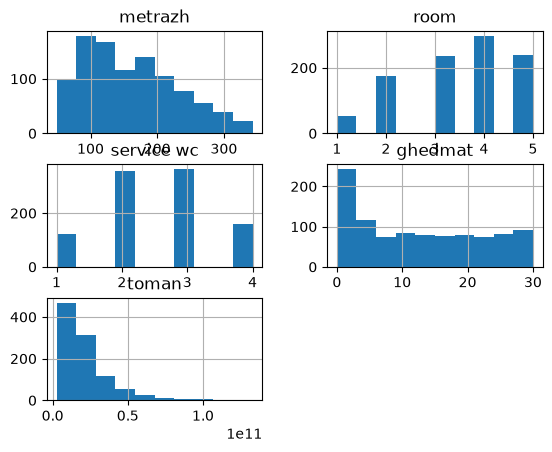

In [24]:
melk=df [['address','metrazh','room','service wc', 'ghedmat', 'toman']]
melk.hist()
plt.show()

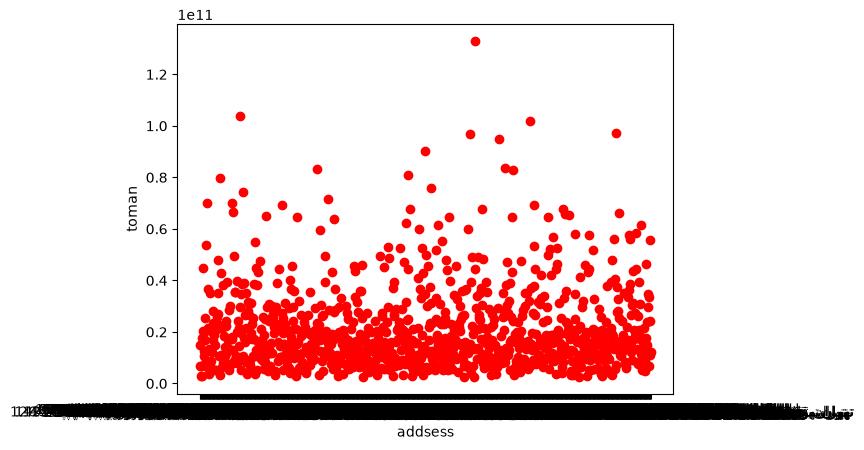

In [25]:
plt.scatter(amlak.address, amlak.toman, color="red")
plt.xlabel("addsess")
plt.ylabel("toman")
plt.show()

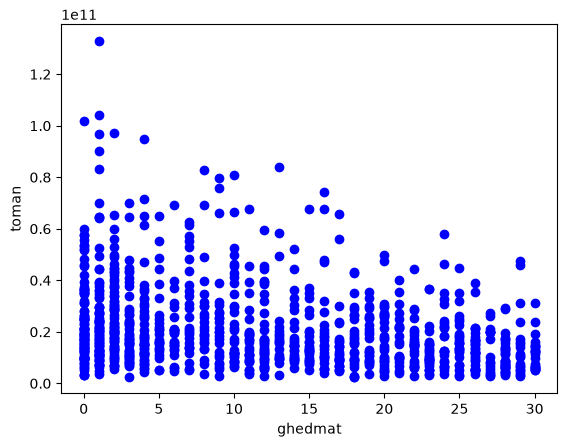

In [26]:
plt.scatter(amlak.ghedmat, amlak.toman, color="blue")
plt.xlabel("ghedmat")
plt.ylabel("toman")
plt.show()

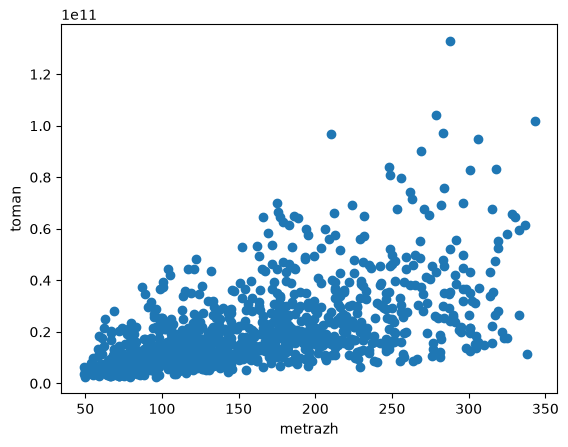

In [27]:
plt.scatter(amlak.metrazh, amlak.toman)
plt.xlabel("metrazh")
plt.ylabel("toman")
plt.show()

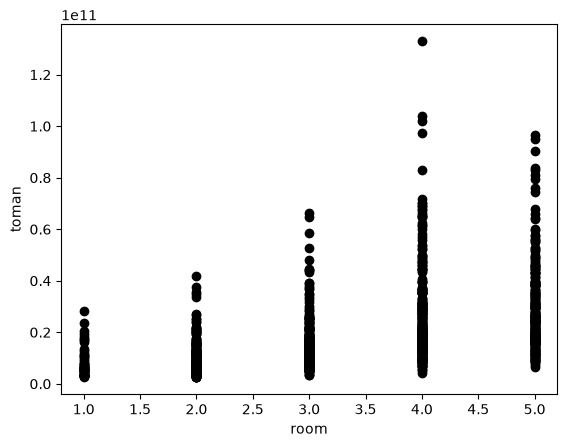

In [28]:
plt.scatter(amlak.room, amlak.toman, color="black")
plt.xlabel("room")
plt.ylabel("toman")
plt.show()

In [29]:
msk=np.random.rand(len(df)) > 0.8
train = amlak[msk]
test = amlak[~msk]

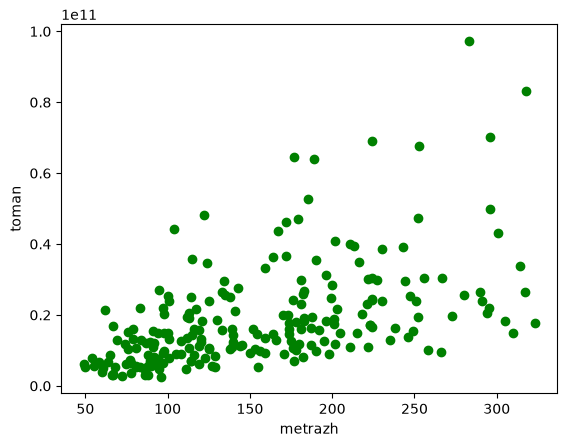

In [30]:
plt.scatter(train.metrazh, train.toman, color="green")
plt.xlabel("metrazh")
plt.ylabel("toman")
plt.show()

In [31]:
from sklearn import linear_model
regr=linear_model.LinearRegression()
train_x =np.asanyarray(train[['metrazh']])
train_y =np.asanyarray(train[['toman']])
regr.fit(train_x,train_y)

print('coeffication:' , regr.coef_)
print('intercept:' , regr.intercept_) 

coeffication: [[1.14258799e+08]]
intercept: [1.25126707e+09]


Text(0, 0.5, 'toman')

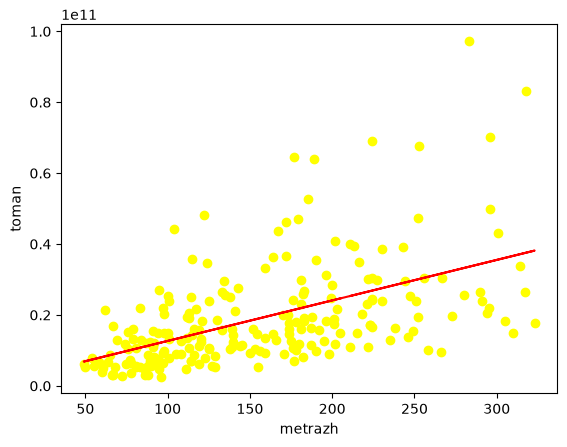

In [32]:
plt.scatter(train.metrazh, train.toman,  color='yellow')
plt.plot(train_x, regr.coef_[0][0]*train_x + regr.intercept_[0],'-r')
plt.xlabel("metrazh")
plt.ylabel("toman")

In [33]:
from sklearn.metrics import r2_score

test_x = np.asanyarray(test[['metrazh']])
test_y = np.asanyarray(test[['toman']])
test_y_ = regr.predict(test_x)

print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y , test_y_) )

Mean absolute error: 9204041876.73
Residual sum of squares (MSE): 190793519374667644928.00
R2-score: 0.30
